# DSA 4060XA – Week 6 Guided Practical Lab
## Evaluating Recommender Systems

**Name:** J. P. Chawanda
**Student ID:** 670444
**Date:** 26 October 2026

### Lab objective

Build three recommenders over the same movie-rating data — a popularity baseline, a
content-based model and an item-based collaborative-filtering model — and evaluate them
on three different families of metric:

1. **Rating prediction accuracy** — MAE and RMSE.
2. **Ranking quality** — Precision@K, Recall@K and NDCG@K over Top-3 lists.
3. **Beyond-accuracy behaviour** — catalogue coverage, novelty and diversity.

The point of the lab is that these three families disagree, so "best model" is only
meaningful once a business objective is stated.

## Step 1 – Import the Required Libraries

All imports live in one place so the notebook is reproducible from a fresh kernel.
`TOP_K = 3` fixes the recommendation list length used throughout.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

`movies` holds item metadata, `ratings` holds explicit user–movie feedback on a 1–5 scale.

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


### Student Check

1. **What does one row in `movies` represent?** One movie in the catalogue, with its id,
   title and a pipe-separated genre list. This is the item-side metadata the
   content-based model will use.
2. **What does one row in `ratings` represent?** One rating event — a single user giving a
   single movie a score, with a timestamp that orders that user's activity.
3. **How many unique users and movies are present?** 12 users and 20 movies, giving 120
   ratings. Every user has rated exactly 10 movies, so the matrix is 50% dense — far
   denser than any real catalogue.
4. **What type of feedback is the `rating` column?** Explicit feedback: the user actively
   states a preference level, rather than us inferring it from a click or a watch.
5. **What is the rating scale?** Nominally 1–5. In this sample only 2, 3, 4 and 5 actually
   occur — nobody gave a 1.

## Step 3 – Inspect Rating Behaviour

Rating distributions matter before evaluation. If almost every rating is high, a model can
look good simply by predicting "high" for everything, and the relevance threshold used for
ranking metrics will mark almost everything relevant.

In [3]:
display(ratings["rating"].value_counts().sort_index())

print("Mean rating:", round(ratings["rating"].mean(), 3))
print("Share of ratings >= 4:", round((ratings["rating"] >= 4).mean(), 3))

rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

Mean rating: 3.225
Share of ratings >= 4: 0.35


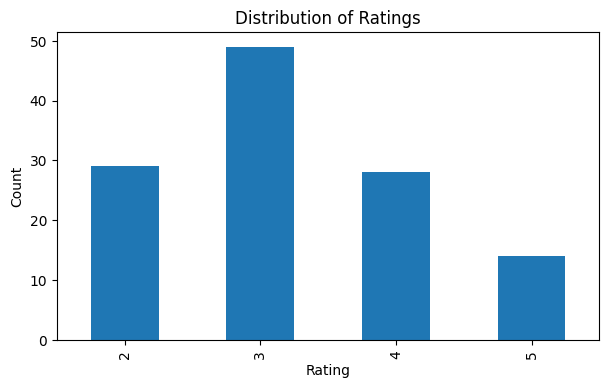

In [4]:
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

### Interpretation

The distribution is centred, not top-heavy: 3 is the single most common rating (49 of 120),
and the mean is 3.23. Unusually for rating data there is no positivity skew — low ratings
(29 twos) slightly outnumber top ratings (14 fives), and no 1s appear at all.

Two consequences for evaluation. First, a constant predictor near 3.2 is already a
respectable rating-prediction model, so MAE and RMSE will not separate the three models by
much. Second, only 35% of ratings reach the "relevant" threshold of 4, so when we hold out
one rating per user most held-out items will be *irrelevant* — the ranking metrics will be
computed on a handful of users and will be very noisy.

## Step 4 – Create a Train/Test Split

For every user, hold out the most recent interaction as test data. This leave-one-last-out
split gives each user a training history while leaving one genuinely unseen interaction to
evaluate against.

In [5]:
ratings = ratings.sort_values(["user_id", "timestamp"])

test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


**Why this matters:** evaluation must use interactions the model did not learn from. If we
scored the models on the training ratings, the collaborative-filtering model in particular
would be reading back answers it had already memorised, and every number below would be
optimistic. Holding out the *most recent* interaction also mimics production use: we learn
from the past and predict the future, rather than learning from the future.

## Step 5 – Build a Popularity Baseline

A baseline is the reference the advanced models must beat to justify their complexity.

* For rating prediction: predict each movie's average training rating.
* If a movie has no training rating: fall back to the global training mean.
* For ranking: order movies by average rating, then rating count.

In [6]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10)

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


In [7]:
movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

display(baseline_test.head())

,user_id,movie_id,rating,timestamp,prediction
9,1,14,4,10,2.857143
19,2,9,4,20,3.000000
29,3,18,3,30,4.000000
39,4,18,3,40,4.000000
49,5,11,2,50,2.500000


## Step 6 – Evaluate the Baseline with MAE and RMSE

| Metric | Meaning | Direction |
|---|---|---|
| MAE | Average absolute difference between actual and predicted ratings | Lower is better |
| RMSE | Like MAE but penalises large errors more strongly | Lower is better |

In [8]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse


baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


**Interpretation:** an MAE of 1.09 means the baseline is wrong by roughly one full rating
point on a 1–5 scale. RMSE (1.20) sits above MAE, which tells us the errors are not evenly
sized — a few held-out ratings are missed badly, and RMSE's squaring makes those dominate.

## Step 7 – Build Item Features for Content-Based Filtering

Turn each movie's genre string into binary features: `Action|Sci-Fi` becomes
`Action = 1`, `Sci-Fi = 1`, every other genre 0.

In [9]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

print("Genre features:", genre_columns)
display(content_items.head())

Genre features: ['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Family', 'Mystery', 'Romance', 'Sci-Fi']


,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


## Step 8 – Build a User Preference Profile

For each user: take the movies rated in training, weight each movie's genre vector by the
rating the user gave it, and average. The result is a genre-space vector pointing towards
what the user likes.

In [10]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values

    return (features * ratings_array).mean(axis=0)


profile = build_user_profile(1, train)

pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

In [11]:
# The movies behind User 1's profile, for the check below.
(
    train[train["user_id"] == 1]
    .merge(movies, on="movie_id")[["title", "genres", "rating"]]
    .sort_values("rating", ascending=False)
)

,title,genres,rating
2,Galaxy Mission,Action|Sci-Fi,5
6,Digital Dreams,Sci-Fi|Drama,4
0,Love in Nairobi,Romance|Drama,3
1,Hidden Truth,Drama|Mystery,3
3,Wedding Weekend,Romance|Comedy,3
4,City Detectives,Crime|Drama,3
8,Family Weekend,Comedy|Family,3
5,Home Again,Family|Drama,2
7,Weekend Escape,Comedy|Adventure,2


### Student task – User 1's strongest preferences

User 1's profile ranks **Drama (1.67)** first and **Sci-Fi (1.00)** second.

These only partly agree with the user's highly rated movies. Sci-Fi agrees strongly: User 1's
two best ratings are *Galaxy Mission* (Action|Sci-Fi, 5) and *Digital Dreams*
(Sci-Fi|Drama, 4), so Sci-Fi earns a high weight from genuinely high ratings.

Drama is more of an artefact. It tops the profile because it appears in four of the nine
training movies — *Love in Nairobi*, *Hidden Truth*, *City Detectives*, *Home Again* — but
all of those were rated only 3, 3, 3 and 2. Frequency, not enthusiasm, pushes it to the
top. This exposes a real weakness of the rating-weighted-average profile: because every
rating in the data is positive (no 1s, and 2 still adds weight), a genre the user is
lukewarm about but sees often outranks a genre they love but saw twice. Mean-centring the
ratings before weighting would fix this.

## Step 9 – Content-Based Rating Prediction

Compare the user profile with each item vector by cosine similarity, then map the
similarity onto the 1–5 scale with `1 + 4 * sim`.

In [12]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)

    sim = cosine_similarity(profile, item_vec)[0, 0]

    return float(np.clip(1 + 4 * sim, 1, 5))


content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))
print("Prediction range:",
      round(content_test["prediction"].min(), 3), "to",
      round(content_test["prediction"].max(), 3))

Content MAE: 1.094
Content RMSE: 1.381
Prediction range: 1.591 to 3.992


**Note on this conversion.** `1 + 4 * sim` is a teaching convenience, not a calibrated
predictor. Cosine similarity measures *direction* in genre space, not how much the user
liked anything, so the mapping is arbitrary: here it spreads predictions across 1.59–3.99
while the actual held-out ratings average 3.2. That mismatch is why the content model's
RMSE comes out worst of the three even though its ranking behaviour is the best. Judge this
model on its Top-N results, not its MAE.

## Step 10 – Build Item-Based Collaborative Filtering

Collaborative filtering ignores metadata and uses behaviour: two movies are similar when
users rate them in similar ways.

In [13]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


One caveat worth naming: `fillna(0)` treats "not rated" as a rating of zero. With a 50%
dense matrix that means similarity is driven substantially by *co-rating* — which movies the
same people happened to rate — rather than by agreement on how good they are. Two movies
rated by the same crowd look similar even if that crowd disagreed about them.

## Step 11 – Item-Based Rating Prediction

For a target movie, take the movies the user already rated, weight their ratings by
similarity to the target, and average.

In [14]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    weighted_sum = 0.0
    similarity_sum = 0.0

    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]

            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum


cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))
print("Prediction range:",
      round(cf_test["prediction"].min(), 3), "to",
      round(cf_test["prediction"].max(), 3))

CF MAE: 0.924
CF RMSE: 1.07
Prediction range: 2.744 to 3.476


**Why CF wins on MAE — and why that is less impressive than it looks.** The CF predictions
span only 2.74–3.48, a range of 0.73 rating points. Because every similarity is positive,
the weighted average is pulled towards each user's mean rating, so the model is effectively
predicting "about 3.2" with a small personalised nudge. On a dataset whose true mean is
3.23 and whose ratings cluster on 3, that cautious strategy minimises average error almost
by construction. Low MAE here signals a well-centred predictor, not a model that knows who
will love what — and Step 15 confirms the distinction.

## Step 12 – Compare Rating Prediction Metrics

In [15]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


### Student Check

6. **Which model has the lowest MAE?** Item-Based CF, at 0.924 against the baseline's
   1.086.
7. **Which model has the lowest RMSE?** Item-Based CF again, at 1.070 against 1.201. The
   content model is worst on RMSE (1.381), penalised for the uncalibrated
   similarity-to-rating conversion in Step 9.
8. **Does either advanced model clearly beat the baseline?** Not clearly, no. CF improves
   MAE by 0.16 rating points — a real direction, but measured on **12 held-out ratings**.
   One user's prediction moving by two points would swing MAE by ~0.17 and erase the gap,
   so the margin is inside the noise of a sample this size. The content model does not beat
   the baseline on either metric. The honest reading is that no model has demonstrated it
   earns its complexity on rating accuracy.
9. **Why avoid declaring a model best from only one metric?** Because the metrics here
   actively disagree. CF wins both rating metrics and then scores **zero** on Precision@3,
   Recall@3 and NDCG@3 in Step 15 — it predicts the rating level well but puts the wrong
   movies at the top of the list. A single metric also hides whether a model is merely
   predicting near the mean, which is exactly what CF turns out to be doing. Which metric
   you optimise should follow from what the product actually does: predict a score, or
   choose a short list.

## Step 13 – Move from Rating Prediction to Ranking Evaluation

Most production recommenders never show a predicted rating — they show a short list. So we
evaluate Top-3 list quality instead.

**Relevance rule:** a held-out item counts as relevant if its actual rating is 4 or 5.

In [16]:
test["relevant"] = test["rating"] >= 4

display(test[["user_id", "movie_id", "rating", "relevant"]])

print("Users with a relevant held-out item:", int(test["relevant"].sum()), "of", len(test))

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False
59,6,2,5,True
69,7,3,2,False
79,8,12,2,False
89,9,16,2,False
99,10,19,3,False


Users with a relevant held-out item: 5 of 12


Only **5 of 12 users** have a relevant held-out item, and each of those users has exactly
one. This is the single most important caveat on every ranking number below: each model
gets 5 users × 3 slots = 15 chances to surface 5 specific movies, and the ranking averages
are taken over just those 5 users. One lucky hit moves Precision@3 by 0.067.

## Step 14 – Build Top-N Recommendation Functions

Each recommender scores the movies a user has *not* seen in training and returns the top K.

In [17]:
all_movie_ids = movies["movie_id"].tolist()


def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]


popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)


def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]


def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]


def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

In [18]:
title_map = movies.set_index("movie_id")["title"].to_dict()

for name, recs in [
    ("Popularity   ", recommend_popularity(1, TOP_K)),
    ("Content      ", recommend_content(1, TOP_K)),
    ("Collaborative", recommend_cf(1, TOP_K)),
]:
    print(f"{name}: {recs}  ->  {[title_map[m] for m in recs]}")

Popularity   : [6, 18, 16]  ->  ['Broken Hearts', 'The Promise', 'Campus Life']
Content      : [16, 6, 18]  ->  ['Campus Life', 'Broken Hearts', 'The Promise']
Collaborative: [12, 11, 18]  ->  ['The Last Case', 'Laugh Out Loud', 'The Promise']


### Discussion

For User 1 the three lists are:

| Model | Top-3 |
|---|---|
| Popularity | Broken Hearts, The Promise, Campus Life |
| Content-Based | Campus Life, Broken Hearts, The Promise |
| Collaborative | The Last Case, Laugh Out Loud, The Promise |

**Which is most personalised?** Collaborative filtering, by a clear margin — it is the only
list whose *membership* differs from the popularity list. Note how damning the comparison
is for the content model: it recommends exactly the same three movies as the baseline,
merely reordered. That is the Drama artefact from Step 8 at work. Because User 1's profile
is dominated by the most common genres, the model's favourites are the catalogue's most
common genres, which are also the movies that accumulated high average ratings. The
coverage numbers in Step 16 confirm this is systematic, not a one-user coincidence.

**Which is easiest to explain?** Popularity, trivially ("these are our highest-rated
films"). Content-based is a close and more useful second — "because you watch Sci-Fi and
Drama" is a sentence you can put in the UI. CF is hardest: "users who rated *The Last Case*
also rated things you rated" is both wordier and, given the `fillna(0)` co-rating effect,
not strictly what the model computed.

## Step 15 – Precision@K, Recall@K, and NDCG@K

| Metric | Question answered |
|---|---|
| Precision@K | Of the K recommended items, how many are relevant? |
| Recall@K | Of all relevant test items, how many were recovered? |
| NDCG@K | Were relevant items placed near the top of the list? |

In [19]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))

    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan

    return precision, recall


def ndcg_at_k(recs, relevant, k):
    dcg = 0.0

    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else np.nan

In [20]:
def evaluate_ranking(recommender, k=3):
    rows = []

    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        if not relevant:
            continue

        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)

    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

In [21]:
pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


### Interpretation

The ranking picture inverts the rating picture. Item-Based CF — the MAE and RMSE winner —
scores **0.000 on all three ranking metrics**. It never once placed a relevant held-out
movie in a user's Top-3. Popularity and Content tie on Precision@3 and Recall@3 (0.067 and
0.200, one hit each across the five evaluated users), and the content model wins NDCG@3
(0.200 vs 0.100) because its hit landed at rank 1 rather than rank 3.

That NDCG gap is the whole argument for the metric: identical Precision, identical Recall,
but one model put the right movie where the user would actually see it.

All of these absolute values are low, and deliberately so — with 5 relevant items, 3 slots
and 11-plus candidates per user, random guessing would score near 0.09 Precision@3. The
models are performing around chance. What is interpretable is the *ordering* between them,
and the fact that CF's zero is a structural failure rather than bad luck: because its
predictions are squeezed into 2.74–3.48, its ranking is driven by tiny differences in a
near-constant score.

## Step 16 – Catalogue Coverage

Coverage measures how much of the catalogue ever gets shown. A model that recommends the
same few hits to everyone has low coverage, however accurate it looks.

In [22]:
def catalogue_coverage(recommender, k=3):
    recommended = set()

    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))

    return len(recommended) / movies["movie_id"].nunique()


coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


Coverage separates the models far more sharply than any accuracy metric did: **0.35** for
popularity, **0.70** for content, **0.85** for CF.

The baseline shows just 7 distinct movies across all 12 users — 13 of 20 titles are never
recommended to anyone, and the only reason it reaches 7 rather than 3 is that each user's
already-seen movies get filtered out, forcing it down its fixed ranking. CF reaches 17 of
20 titles. This is the metric that answers management's "we don't want the same titles
dominating", and it is the one where the baseline fails outright.

## Step 17 – Novelty

Novelty rewards recommending items that are not already ubiquitous, scoring each item by
`-log2(p)` where `p` is the share of users who interacted with it.

In [23]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()


def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)


def average_novelty(recommender, k=3):
    values = []

    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])

    return np.mean(values)


novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


CF is highest (1.695), the baseline essentially ties it (1.689), and content-based is
*lowest* (1.344).

The baseline scoring as highly as CF is a quirk worth explaining rather than glossing over.
This novelty measure counts *rating frequency*, while the baseline ranks by *mean rating*
with count only as a tie-break. Its favourites — *Broken Hearts* (6 ratings), *The Promise*
(2 ratings) — are well-liked, not widely rated, so they look novel to this metric. In other
words, novelty-by-interaction-count and coverage are not measuring the same thing here, and
coverage is the more trustworthy signal of concentration: the baseline's 0.35 coverage shows
it really is showing everyone the same handful of films, even though its novelty score
doesn't flag it.

The content model being least novel fits Step 14: it gravitates to the biggest genre
clusters, which are also the most-rated movies.

## Step 18 – Diversity

Diversity asks whether the items *within one list* differ from each other. We average the
pairwise genre cosine similarity inside each list and take `1 - mean similarity`.

In [24]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)


def list_diversity(movie_ids):
    sims = []

    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )

    return 1 - np.mean(sims) if sims else 0


def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])


diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


CF is most diverse (0.780), popularity next (0.736), content-based clearly least (0.542).

Content-based scoring lowest is not a defect — it is the model working as designed. It
selects items *because* they match one genre profile, so the three winners resemble each
other by construction. This is the classic content-based filter bubble, and it is the
trade-off you accept for explainability.

Note also that diversity and relevance are not aligned: CF has the most varied lists and
the worst hit rate. A list can be diverse by being indiscriminate.

## Step 19 – Build a Unified Evaluation Table

In [25]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

summary.round(3)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


## Step 20 – Interpret Evaluation Trade-Offs

Every generic trade-off in the brief shows up concretely in the table above:

* **Better RMSE, weaker ranking.** Item-Based CF wins MAE (0.924) and RMSE (1.070) and
  scores 0.000 on Precision@3, Recall@3 and NDCG@3. The clearest result in the lab.
* **High precision, low coverage.** The popularity baseline matches the best Precision@3
  while exposing only 35% of the catalogue.
* **Accurate but only popular.** The baseline is competitive on accuracy precisely
  *because* it recommends established hits — it is the model management explicitly ruled
  out.
* **Diverse and novel but less precise.** CF leads coverage (0.85), novelty (1.695) and
  diversity (0.780), and recovers nothing.
* **Explainable but less accurate.** Content-based gives the one UI-ready reason
  ("because you watch Sci-Fi and Drama") and has the worst RMSE of the three.

There is also a trade-off the brief does not list but this dataset makes vivid: **a model
can win a metric by refusing to commit.** CF's low MAE comes from predicting near the mean
for everything. Error-based metrics reward that hedging; ranking metrics punish it. This is
why MAE and RMSE are the wrong headline metrics for a product that shows lists.

**Key lesson:** there is rarely one universally best recommender. The preferred model
depends on the business objective.

## Step 21 – Final Business Scenario

> "We want users to discover relevant movies, but we do not want the same popular titles to
> dominate every recommendation list."

**10. Which model would you choose?**

**Content-based filtering**, as the model to deploy now.

The objective has two clauses, and the choice has to satisfy both. On *relevance*, content
ties the baseline on Precision@3 and Recall@3 and wins NDCG@3 outright (0.200 vs 0.100) —
it is the only model that put a relevant item at rank 1. On *not being dominated by popular
titles*, it doubles the baseline's coverage (0.70 vs 0.35). It is the only model that is not
disqualified by one clause or the other: the baseline fails the anti-popularity clause
(0.35 coverage), and CF fails the relevance clause (0.000 on every ranking metric) despite
winning coverage, novelty and diversity. Being first past both bars matters more here than
leading any single column.

Its weaknesses are real and I would plan around them rather than deny them: lowest
diversity (0.542), lowest novelty (1.344), and the Step 14 finding that for User 1 it
recommended the same three films as the baseline in a different order. I would ship it with
an explicit diversity re-rank — cap the Top-3 at two movies sharing a dominant genre — which
addresses the weakness the table identifies without touching the relevance signal.

**11. Which 2–3 metrics influenced your choice most?**

* **Coverage (0.35 / 0.70 / 0.85)** — the direct measurement of "the same titles dominating",
  and the metric that eliminates the baseline.
* **NDCG@3 (0.100 / 0.200 / 0.000)** — the only metric that separates popularity from content,
  and the one that matches a UI showing a short ranked list where position matters.
* **Precision@3 / Recall@3** — used as a floor rather than a ranking: CF's zero rules it out
  regardless of how well it scores elsewhere.

I deliberately did **not** weight MAE and RMSE heavily. They favour CF, and Step 11 showed
CF earns them by predicting near the mean — behaviour that is worthless for choosing a
three-item list.

**12. What trade-off are you accepting?**

Narrower lists in exchange for more reliable relevance. Content-based has the least internal
variety of the three and the lowest novelty, so users get recommendations near what they
already watch — the filter-bubble risk. I am also giving up the 0.16 MAE advantage CF
holds, which is acceptable because the product ranks items rather than displaying predicted
scores. The concrete cost is the 2–3 users whose tastes sit between genre clusters, whom a
genre-profile model serves poorly; the diversity re-rank and a small random-exploration slot
are the mitigations.

**13. State one limitation of this evaluation.**

The ranking metrics rest on **5 users with one relevant item each**. Precision@3 moves in
steps of 0.067 per hit, so the entire content-vs-popularity NDCG gap is a single hit landing
at rank 1 instead of rank 3. The decision above is directionally reasonable but is not
statistically supported — on this data I would treat it as a hypothesis to test with an
online A/B test, not a settled result.

## Step 22 – Extension Challenge

**Option A – Change K:** evaluate K = 1, 3 and 5, then explain how Precision@K and
Recall@K change.

First, a fix. The `evaluate_ranking` function in Step 15 hardcodes its output keys as
`"Precision@3"` regardless of the `k` passed in, so sweeping K with it would silently
mislabel every row. The version below takes the label from `k`.

In [26]:
def evaluate_ranking_k(recommender, k):
    rows = []

    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        if not relevant:
            continue

        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)

    return {
        "Precision@K": result["Precision@K"].mean(),
        "Recall@K": result["Recall@K"].mean(),
        "NDCG@K": result["NDCG@K"].mean()
    }


recommenders = [
    ("Popularity Baseline", recommend_popularity),
    ("Content-Based", recommend_content),
    ("Item-Based CF", recommend_cf),
]

k_rows = []
for k in (1, 3, 5):
    for name, rec in recommenders:
        k_rows.append({"K": k, "Model": name, **evaluate_ranking_k(rec, k)})

k_results = pd.DataFrame(k_rows)
k_results.round(3)

,K,Model,Precision@K,Recall@K,NDCG@K
0,1,Popularity Baseline,0.000,0.0,0.000
1,1,Content-Based,0.200,0.2,0.200
2,1,Item-Based CF,0.000,0.0,0.000
3,3,Popularity Baseline,0.067,0.2,0.100
4,3,Content-Based,0.067,0.2,0.200
5,3,Item-Based CF,0.000,0.0,0.000
6,5,Popularity Baseline,0.040,0.2,0.100
7,5,Content-Based,0.080,0.4,0.277
8,5,Item-Based CF,0.040,0.2,0.077


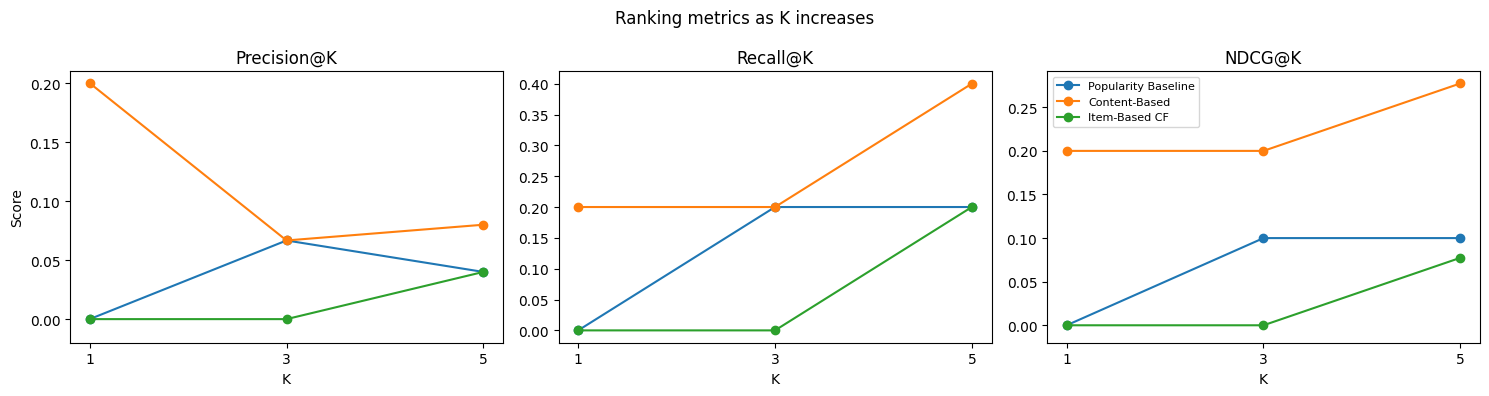

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for ax, metric in zip(axes, ["Precision@K", "Recall@K", "NDCG@K"]):
    for name, _ in recommenders:
        subset = k_results[k_results["Model"] == name]
        ax.plot(subset["K"], subset[metric], marker="o", label=name)
    ax.set_title(metric)
    ax.set_xlabel("K")
    ax.set_xticks([1, 3, 5])
    ax.set_ylim(bottom=-0.02)

axes[0].set_ylabel("Score")
axes[2].legend(loc="upper left", fontsize=8)
plt.suptitle("Ranking metrics as K increases")
plt.tight_layout()
plt.show()

### How Precision@K and Recall@K change

| K | Model | Precision@K | Recall@K | NDCG@K |
|---:|---|---:|---:|---:|
| 1 | Popularity Baseline | 0.000 | 0.000 | 0.000 |
| 1 | Content-Based | 0.200 | 0.200 | 0.200 |
| 1 | Item-Based CF | 0.000 | 0.000 | 0.000 |
| 3 | Popularity Baseline | 0.067 | 0.200 | 0.100 |
| 3 | Content-Based | 0.067 | 0.200 | 0.200 |
| 3 | Item-Based CF | 0.000 | 0.000 | 0.000 |
| 5 | Popularity Baseline | 0.040 | 0.200 | 0.100 |
| 5 | Content-Based | 0.080 | 0.400 | 0.277 |
| 5 | Item-Based CF | 0.040 | 0.200 | 0.077 |

**Recall rises monotonically with K, Precision generally falls.** This is the textbook
trade-off and both halves are visible here. A longer list can only ever contain more of the
relevant items, so Recall never decreases: content-based goes 0.200 → 0.200 → 0.400 as a
second user's held-out movie enters the list at K=5, and CF goes 0.000 → 0.000 → 0.200 when
its first hit finally appears at K=5. Precision, by contrast, divides by K, so an unchanged
number of hits is diluted: the baseline's single hit gives 1/3 = 0.067 at K=3 and 1/5 =
0.040 at K=5.

**Precision can rise with K when a new hit outpaces the dilution.** Content-based goes from
0.067 at K=3 to 0.080 at K=5 — it picks up a second hit (1/3 → 2/5), and 2/5 > 1/3. So the
"precision always falls" shorthand is really "precision falls unless the longer list adds
hits faster than it adds slots".

**Why the ceiling on Recall is structural, not model weakness.** Each evaluated user has
exactly one relevant held-out item, so per-user Recall@K is either 0 or 1 and the mean is
just *the fraction of the 5 users whose item was found*. Recall@K here is a hit-rate in
disguise. It also means Recall could in principle hit 1.0 at K=1 — nothing about a short
list caps it — which is not true of the usual multi-item-per-user setting.

**K=1 is the most discriminating setting, and it reorders the models.** At K=1 content-based
scores 0.200 on all three metrics while *both* other models score zero: it is the only model
whose single best guess was ever right. Precision@1 is the strictest test available and the
one that most closely matches a "hero slot" or autoplay UI. Note how differently the models
rank at K=1 (content clearly ahead) versus K=3 (content and popularity tied) — choosing K
is a modelling decision, not a reporting detail, and it should mirror how many items the
product actually shows.

**The caveat still applies.** Every number in this table comes from 5 users, so each
Precision@5 cell moves in steps of 0.04 and each Recall cell in steps of 0.2. The shapes of
the curves are the finding; the exact values are not.

## Summary of Findings

| | Rating accuracy | Ranking quality | Catalogue behaviour |
|---|---|---|---|
| **Popularity Baseline** | Middling (MAE 1.086) | Tied best Precision/Recall, weak NDCG | Worst — 0.35 coverage |
| **Content-Based** | Worst (RMSE 1.381) | Best NDCG@3, best at K=1 and K=5 | Mid coverage, least diverse |
| **Item-Based CF** | Best (MAE 0.924) | Worst — zero at K=1 and K=3 | Best coverage, novelty, diversity |

No model wins across the board, and the model that wins rating accuracy is the one that
fails ranking hardest. For the stated objective — relevant discovery without popular titles
dominating — **content-based filtering with a diversity re-rank** is the recommendation,
held as a hypothesis for online testing rather than a conclusion, given that five users
supply every ranking number above.